# K-means clustering trên bộ dữ liệu Iris

> Notebook thực hành đi kèm Chapter 10 (`resources/notebook-chap10.md`): phân cụm K-means.

**Mục tiêu:** sau notebook này bạn có thể

- khám phá dữ liệu (EDA) trước khi phân cụm;
- chuẩn hóa đặc trưng bằng z-score (mục 10.5.3);
- chọn số cụm K bằng Elbow và Silhouette (mục 10.5.2);
- chạy `KMeans` của scikit-learn rồi đánh giá bằng nhãn thật mà K-means không được thấy (crosstab, ARI).

**Môi trường:** Python 3 với `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn` (đều có sẵn trên Google Colab). Chạy các cell **theo thứ tự từ trên xuống**, vì cell sau dùng biến của cell trước.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns  # biểu đồ thống kê, xây dựng trên matplotlib

# Chuẩn bị dữ liệu

Dùng trực tiếp bộ **Iris** có sẵn trong `sklearn.datasets`: 150 bông hoa thuộc 3 loài (setosa, versicolor, virginica), mỗi bông có 4 đặc trưng đo bằng cm (chiều dài và chiều rộng của đài hoa *sepal* và của cánh hoa *petal*). Cột `species` chỉ dùng để đối chiếu ở cuối bài, K-means **không** được thấy nó.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


# Exploratory Data Analysis - EDA

Trước khi chạy bất kỳ thuật toán nào, việc đầu tiên một người làm dữ liệu cần làm là **hiểu dữ liệu của mình**. Đây là bước dễ bị bỏ qua nhất, nhưng lại quyết định chất lượng của toàn bộ bài toán phía sau.

## Vì sao khám phá dữ liệu quan trọng?

K-means là thuật toán **không có giám sát**: nó không biết "đáp án đúng" là gì, chỉ dựa vào **khoảng cách** giữa các điểm dữ liệu. Vì vậy, nếu không hiểu dữ liệu, ta rất dễ nhận về kết quả sai mà không hề hay biết. Khám phá dữ liệu giúp ta:

- **Biết dữ liệu có gì:** bao nhiêu mẫu, bao nhiêu đặc trưng (feature), kiểu dữ liệu của từng cột.
- **Phát hiện vấn đề sớm:** giá trị thiếu, giá trị trùng lặp, ngoại lai (outlier).
- **Kiểm tra thang đo:** K-means dùng khoảng cách, nên đặc trưng có giá trị lớn sẽ "lấn át" đặc trưng có giá trị nhỏ. Nếu các đặc trưng khác thang đo, ta cần một bước chuẩn hóa.
- **Đưa ra giả thuyết hợp lý:** dữ liệu có vẻ chia thành mấy nhóm? Điều này giúp ta chọn số cụm *k* có cơ sở, thay vì đoán mò.
- **Diễn giải kết quả về sau:** hiểu ý nghĩa của từng đặc trưng thì mới giải thích được vì sao các điểm lại thuộc cùng một cụm.

> **Nguyên tắc cần nhớ:** *"Garbage in, garbage out"*: dữ liệu đầu vào kém hiểu biết hoặc kém chất lượng thì kết quả phân cụm dù chạy không báo lỗi vẫn có thể vô nghĩa.

## Quy trình khám phá

1. **Xem tổng quan:** dùng `head()`, `shape`, `info()` để biết kích thước và kiểu dữ liệu.
2. **Thống kê mô tả:** dùng `describe()` để xem giá trị trung bình, nhỏ nhất, lớn nhất của từng đặc trưng. Các đặc trưng có cùng thang đo không?
3. **Kiểm tra chất lượng:** có giá trị thiếu hoặc dòng trùng lặp không?
4. **Trực quan hóa:**
   - Vẽ histogram hoặc boxplot cho từng đặc trưng để xem phân phối và ngoại lai.
   - Vẽ `pairplot` (hoặc scatter plot từng cặp đặc trưng) để quan sát xem dữ liệu có tự nhiên tách thành các nhóm không.
5. **Rút ra nhận xét:** dự đoán dữ liệu có khoảng mấy cụm? Cặp đặc trưng nào phân tách các nhóm rõ nhất?

In [3]:
# ---------- 1a. Xem vài dòng đầu tiên ----------
print("1. Tổng quan")
# head() hiển thị 5 dòng đầu, giúp ta "nhìn tận mắt" dữ liệu trông như thế nào:
print("5 dòng đầu tiên của dữ liệu:")
display(df.head())

# ---------- 1b. Kích thước dữ liệu ----------
# shape trả về (số dòng, số cột)
# Số dòng = số mẫu (mỗi mẫu là 1 bông hoa), số cột = số đặc trưng + cột nhãn
print("\n2. Kích thước dữ liệu")
print(f"Kích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")

# ---------- 1c. Thông tin cấu trúc ----------
# info() cho biết: tên cột, số giá trị KHÔNG thiếu (non-null) và kiểu dữ liệu của từng cột
# Nếu số non-null nhỏ hơn số dòng => cột đó có giá trị bị thiếu
print("\n3. Thông tin cấu trúc")
df.info()

# ---------- 1d. Xem nhãn thật (không bắt buộc) ----------
# Cột 'species' là nhãn loài hoa (0, 1, 2).
# LƯU Ý: K-means là thuật toán không giám sát, nên ta sẽ KHÔNG đưa cột này vào khi phân cụm.
# Ta chỉ dùng nó ở cuối bài để so sánh với kết quả phân cụm.
print("\n4. Số mẫu của từng loài:")
print(df["species"].value_counts())

1. Tổng quan
5 dòng đầu tiên của dữ liệu:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



2. Kích thước dữ liệu
Kích thước dữ liệu: 150 dòng, 6 cột

3. Thông tin cấu trúc
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   target             150 non-null    int64   
 5   species            150 non-null    category
dtypes: category(1), float64(4), int64(1)
memory usage: 6.3 KB

4. Số mẫu của từng loài:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
# ---------- 2. Thống kê mô tả ----------
# describe() tính nhanh các thống kê mô tả cho từng cột số:
#   count: số giá trị không thiếu | mean: trung bình | std: độ lệch chuẩn
#   min / max: giá trị nhỏ nhất / lớn nhất | 25%, 50%, 75%: các tứ phân vị
# Ta chỉ describe 4 cột đặc trưng vì đây là dữ liệu K-means sẽ dùng. "target" và "species" bị bỏ vì chúng là các nhãn thật.
X = df.drop(columns=["target", "species"])

# .T (transpose) xoay bảng để mỗi đặc trưng nằm trên 1 dòng, dễ đọc hơn
# round(2) làm tròn 2 chữ số thập phân cho gọn
display(X.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.84,0.83,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.06,0.44,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.76,1.77,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.20,0.76,0.1,0.3,1.30,1.8,2.5


**Nhận xét sau khi mô tả dữ liệu**

**mean:**

- lớn nhất là sepal length
- nhỏ nhất là petal width

> Nên chú ý tới thang đo

**std:**

- lớn nhất là petal length
- nhỏ nhất là sepal width

> độ lệch chuẩn càng lớn, dữ liệu càng phân tán. Petal length có nhiều "khả năng phân biệt" các mẫu hơn.

**mean, trung vị (50%) và tứ phân vị:**

- petal length có mean là `3.76`, trung vị `4.35` (lớn hơn khá nhiều). Bên cạnh đó, 25% chỉ có `1.6`. Hay nói cách khác có 1 bước nhảy cực lớn giữa hai tứ phân vị.
- petal width cũng có dấu hiệu tương tự

> Các phân bố không đều này chính là manh mối cho việc áp dụng bài toán phân cụm là hợp lý.

**min và max:**

- các đặc trưng dùng cùng đơn vị đo, thang đo lại không giống nhau. min và max của petal length thể hiện một biên độ rộng hơn nhiều so với sepal width và petal width.

> K-means dựa trên khoảng cách, đặc trưng có biên độ lớn sẽ đóng góp nhiều hơn vào khoảng cách và có thể "lấn át" các đặc trưng khác.
> Nên chuẩn hoá để các đặc trưng có sức ảnh hưởng ngang nhau

*Lưu ý:* cả 4 đặc trưng của Iris đều tính bằng cm và chênh lệch không quá cực đoan, nên ở bộ dữ liệu này việc chuẩn hóa không làm kết quả thay đổi dữ dội. Nhưng "không dữ dội" không có nghĩa là "không đổi": kết quả vẫn có thể khác (xem gợi ý thử ở cuối bài). Với dữ liệu thực tế (ví dụ một cột là tuổi, một cột là thu nhập) sự chênh lệch thang đo có thể rất lớn, nên chuẩn hóa vẫn là thói quen tốt.

In [5]:
# ---------- 3. Kiểm tra chất lượng: giá trị thiếu và dòng trùng ----------
# isna().sum().sum(): tổng số ô bị thiếu | duplicated(): đánh dấu dòng trùng với một dòng ĐÃ XUẤT HIỆN TRƯỚC
print("Số giá trị thiếu:", X.isna().sum().sum())
print("Số dòng trùng lặp:", X.duplicated().sum())
# keep=False: đánh dấu cả hai dòng trong cặp trùng để thấy chúng là dòng nào
print("Dòng trùng (index):", X.index[X.duplicated(keep=False)].tolist())

Số giá trị thiếu: 0
Số dòng trùng lặp: 1
Dòng trùng (index): [101, 142]


**Chất lượng dữ liệu:** không có giá trị thiếu. Có **1 cặp dòng trùng** (index 101 và 142, hai bông hoa đo ra cùng 4 số). Đây là đặc điểm đã biết của bản Iris trong scikit-learn; với 150 mẫu, một dòng trùng không ảnh hưởng đáng kể nên ta giữ nguyên. Với dữ liệu thực tế, cần xem dòng trùng là lỗi nhập liệu hay là hai đối tượng thật sự giống nhau.

# Trực quan hoá

In [6]:
# Chọn giao diện có lưới nền để dễ đọc giá trị trên biểu đồ
sns.set_theme(style="whitegrid")

# Chuẩn bị dữ liệu vẽ biểu đồ
X = df.drop(columns=["target", "species"])

# Lưu danh sách tên cột để dùng trong vòng lặp vẽ biểu đồ
features = list(X.columns)

## Histogram - khám phá phân phối

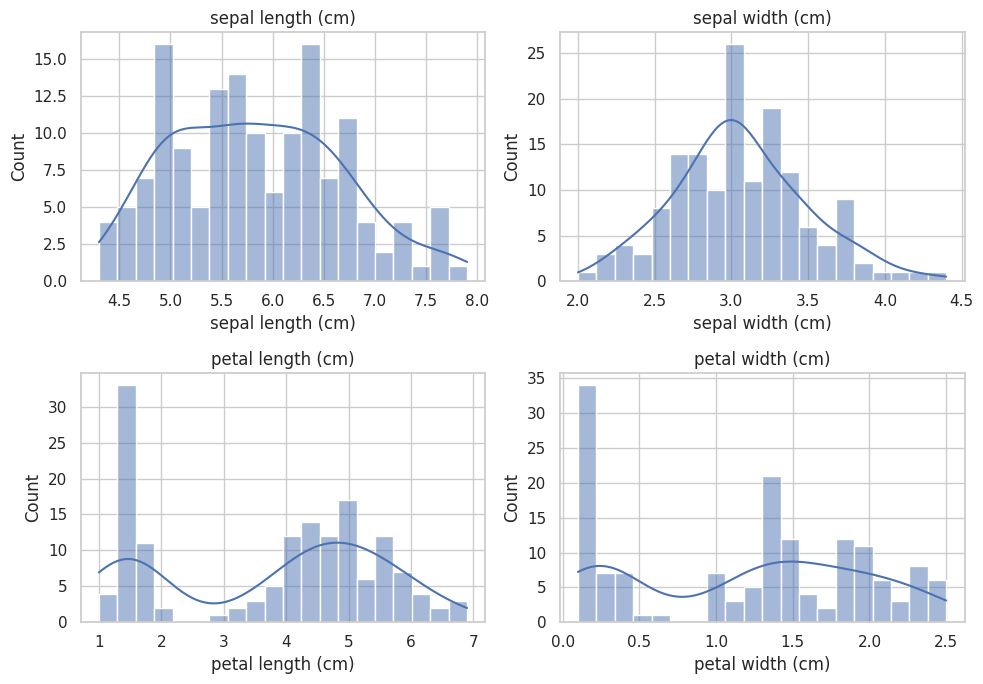

In [7]:
# Tạo lưới 2x2 biểu đồ, mỗi ô dành cho 1 đặc trưng
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# axes.ravel() "duỗi" lưới 2x2 thành danh sách 4 ô để ghép cặp với 4 đặc trưng
for ax, col in zip(axes.ravel(), features):
    # bins=20: chia trục x thành 20 khoảng; kde=True: vẽ thêm đường cong mật độ mượt
    sns.histplot(X[col], bins=20, kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()  # Tự căn chỉnh khoảng cách để các tiêu đề không chồng lên nhau
plt.show()

**Nhận xét:**

- Phân phối gần như một đỉnh: `sepal length` và `sepal width`.
- Phân phối hai đỉnh rõ rệt: `petal length` và `petal width`.

> Các đồ thị đặc biệt là của `petal length` và `petal width` gợi ý dữ liệu gồm **ít nhất hai nhóm tách biệt**: một nhóm có cánh hoa rất nhỏ và một nhóm có cánh hoa lớn hơn. Đây chính là kiểu cấu trúc mà thuật toán phân cụm có thể khai thác.

*Lưu ý:* histogram chỉ nhìn **từng đặc trưng riêng lẻ**, nên chưa đủ để kết luận về số cụm.

> `sepal length` và `sepal width` kém hữu ích hơn trong việc phân biệt các nhóm. Vì phân phối của chúng chỉ có một đỉnh, không có khoảng trống rõ ràng, nên khó "nhìn thấy" ranh giới giữa các nhóm chỉ từ hai đặc trưng này. Các nhóm có thể chồng lấn nhau nhiều ở đây.

## Boxplot - khám phá ngoại lai và thang đo

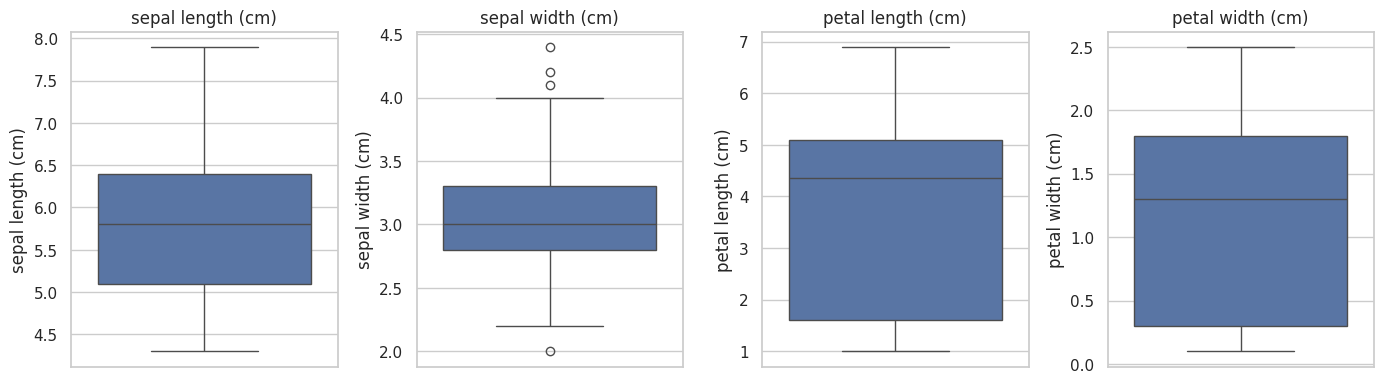

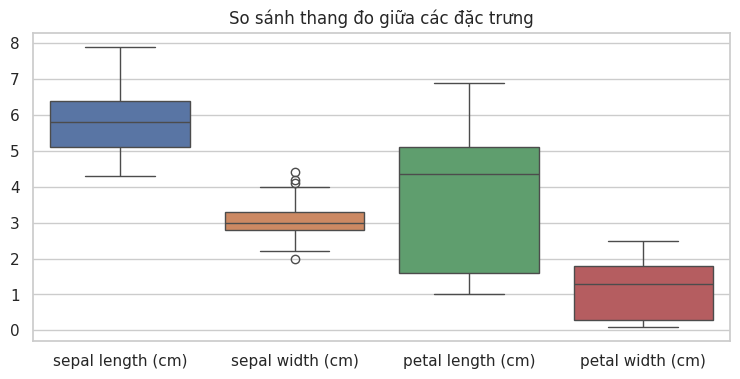

In [8]:
# Biểu đồ 1: mỗi đặc trưng một ô riêng, trục y tự điều chỉnh theo từng đặc trưng
# -> giúp thấy rõ ngoại lai của TỪNG đặc trưng
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, features):
    sns.boxplot(
        y=X[col], ax=ax
    )  # Hộp: từ Q1 đến Q3, vạch giữa là trung vị; chấm ngoài "râu" là ngoại lai
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Biểu đồ 2: cả 4 đặc trưng trên CÙNG một trục
# -> giúp so sánh trực tiếp thang đo giữa các đặc trưng
plt.figure(figsize=(9, 4))
sns.boxplot(data=X)
plt.title("So sánh thang đo giữa các đặc trưng")
plt.show()

**Nhận xét:**

**Về ngoại lai:** trong Iris, `sepal width` là đặc trưng có ngoại lai rõ nhất (khoảng 4 điểm nằm ngoài râu). Ba đặc trưng còn lại gần như không có ngoại lai. Số lượng ngoại lai rất ít so với 150 mẫu, nên ở bài này ta giữ nguyên dữ liệu. Với dữ liệu thực tế, ta cần xem xét ngoại lai là lỗi nhập liệu hay là giá trị hiếm nhưng có thật rồi mới quyết định giữ hay loại.

> **Ngoại lai ảnh hưởng thế nào tới K-means?**
> K-means dùng **giá trị trung bình** để tính tâm cụm, mà trung bình rất nhạy với giá trị cực đoan. Một vài điểm ngoại lai có thể kéo tâm cụm lệch đi, thậm chí tạo ra một cụm riêng chỉ chứa ngoại lai.

**So sánh các hộp với nhau:**

- `petal length` có hộp cao nhất và trải rộng nhất
- `sepal width` và `petal width` nằm trong khoảng hẹp hơn

> Khớp với phần nhận xét tại describe (std - min - max)

> Các đặc trưng **không cùng thang đo**, củng cố việc nên chuẩn hóa dữ liệu trước khi chạy K-means.

## Pairplot - khám phá quan hệ giữa các đặc trưng

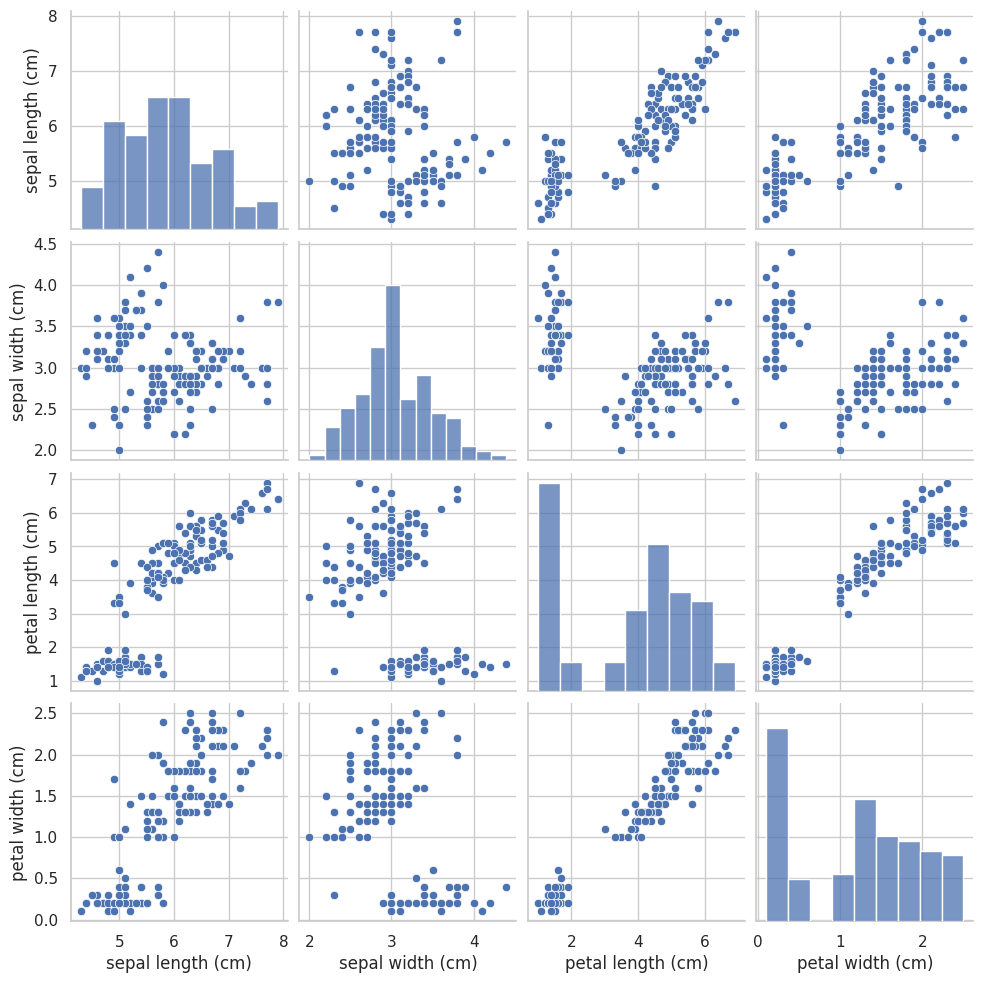

In [9]:
sns.pairplot(X, diag_kind="hist", corner=False)
plt.show()

**Nhận xét:**

- Ở cặp `petal length` và `petal width`, các điểm tạo thành 2 cụm rõ ràng. Đây là manh mối rằng cụm lý tưởng có thể là 2. (tất nhiên khi thực hiện phân cụm, chúng ta thử với nhiều mục tiêu phân cụm hơn, nhưng biểu đồ cho ta một manh mối về giá trị tiềm năng)
- Cặp đặc trưng phân tách các nhóm tốt nhất là các cặp có chứa `petal length` và `petal width`, phân tách cực rõ ràng khi phối hợp với mọi đặc trưng khác.
- Cặp kém nhất là cặp `sepal length` và `sepal width`, các điểm trộn lẫn nhiều, khó thấy ranh giới. (miễn cưỡng có thể nhận ra 2 cụm nhưng độ rõ không thể so được với các cặp chứa đặc trưng về petal).

*Lưu ý:* chỉ từ chừng này manh mối thì chưa thể chọn được K (số cụm mục tiêu) hợp lý. Lý do: mắt người chỉ nhìn được 2 chiều mỗi lần, trong khi dữ liệu có 4 chiều, và ranh giới giữa hai nhóm sát nhau không rõ ràng. Biểu đồ chỉ cho ta **giả thuyết ban đầu** (k = 2 hoặc các giá trị xoay quanh mốc đó như k = 3)

Bước tiếp theo là dùng các phương pháp định lượng như **Elbow** và **Silhouette** để kiểm chứng, rồi so sánh kết quả với dự đoán của bản thân về K.

## Ma trận tương quan (tuỳ chọn)

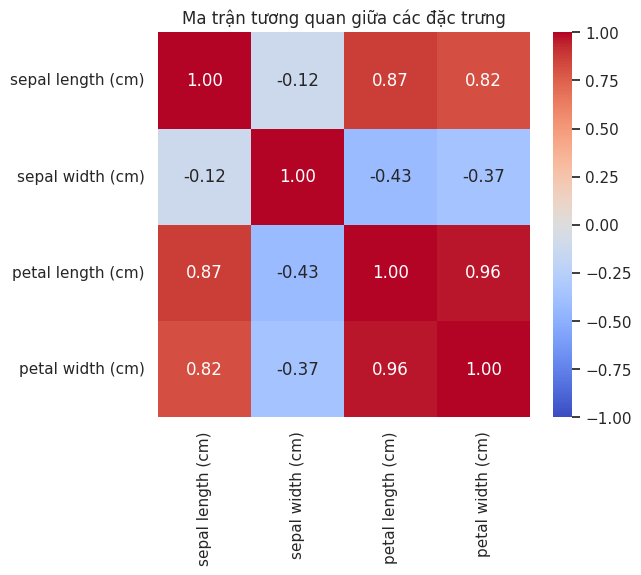

In [10]:
# corr() tính hệ số tương quan Pearson giữa mọi cặp đặc trưng (từ -1 đến 1)
corr = X.corr()

plt.figure(figsize=(6, 5))
# annot=True: ghi số lên từng ô; fmt=".2f": 2 chữ số thập phân
# cmap="coolwarm": đỏ = tương quan dương, xanh = tương quan âm; vmin/vmax cố định thang -1..1
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ma trận tương quan giữa các đặc trưng")
plt.show()

**Nhận xét:**

- Cặp tương quan dương mạnh nhất là `petal length` và `petal width` (hệ số khoảng 0.96). Khi cánh hoa dài hơn thì thường cũng rộng hơn: hai đặc trưng này mang **thông tin gần giống nhau**.
- `sepal width` có tương quan với các đặc trưng khác **yếu hoặc âm**.

Vì `petal length` và `petal width` gần như trùng thông tin, chúng cùng "bỏ phiếu" cho một hướng và làm khoảng cách bị **thiên về hướng đó**. Với Iris điều này không gây vấn đề lớn, nhưng là điều cần để ý với dữ liệu có nhiều đặc trưng tương quan (khi đó người ta có thể giảm chiều bằng PCA).

# Chuẩn hoá dữ liệu

## Vì sao cần chuẩn hóa?

Ở bước khám phá, ta đã thấy các đặc trưng có **biên độ khác nhau**: `petal length` trải từ 1.0 đến 6.9 (rộng khoảng 5.9), trong khi `sepal width` và `petal width` chỉ rộng khoảng 2.4.

K-means gán mỗi điểm vào cụm có tâm gần nhất, và "gần" được đo bằng **khoảng cách Euclid**. Đặc trưng có giá trị biến thiên lớn sẽ đóng góp nhiều hơn vào khoảng cách, nên có thể **lấn át** các đặc trưng còn lại. Chuẩn hóa đưa các đặc trưng về cùng một thang đo để chúng có tầm ảnh hưởng ngang nhau.

## Chuẩn hóa Z-score (StandardScaler)

Mỗi giá trị được biến đổi theo công thức:

$$z = \frac{x - \mu}{\sigma}$$

trong đó $\mu$ là trung bình và $\sigma$ là độ lệch chuẩn của đặc trưng đó. Sau khi biến đổi, mỗi đặc trưng có **trung bình xấp xỉ 0** và **độ lệch chuẩn xấp xỉ 1**. Giá trị $z$ cho biết một điểm nằm cách trung bình bao nhiêu độ lệch chuẩn (ví dụ $z = 2$ nghĩa là cao hơn trung bình 2 độ lệch chuẩn).

In [11]:
from sklearn.preprocessing import (
    StandardScaler,  # Công cụ chuẩn hóa Z-score của scikit-learn
)

# Bước 1: tạo đối tượng scaler
scaler = StandardScaler()

# Bước 2: fit_transform làm 2 việc liên tiếp:
#   - fit: tính trung bình và độ lệch chuẩn của TỪNG cột trong X
#   - transform: áp dụng công thức z = (x - mean) / std cho từng giá trị
# Kết quả là một mảng NumPy (mất tên cột)
X_scaled_array = scaler.fit_transform(X)

# Bước 3: đưa kết quả về lại DataFrame, giữ nguyên tên cột và chỉ số dòng
# để dễ quan sát và dễ vẽ biểu đồ ở các bước sau
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns, index=X.index)

print("5 dòng đầu của dữ liệu SAU khi chuẩn hóa:")
display(X_scaled.head())

# Kiểm tra lại bằng describe(): sau chuẩn hóa, mean phải xấp xỉ 0 và std xấp xỉ 1
# Ta dùng round(2) vì máy tính lưu số thực với sai số rất nhỏ
# (ví dụ mean có thể hiện ra -0.00 hoặc một số cỡ 1e-16 thay vì đúng 0)
display(X_scaled.describe().T.round(2))

5 dòng đầu của dữ liệu SAU khi chuẩn hóa:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,-0.0,1.0,-1.87,-0.90,-0.05,0.67,2.49
sepal width (cm),150.0,-0.0,1.0,-2.43,-0.59,-0.13,0.56,3.09
petal length (cm),150.0,-0.0,1.0,-1.57,-1.23,0.34,0.76,1.79
petal width (cm),150.0,-0.0,1.0,-1.45,-1.18,0.13,0.79,1.71


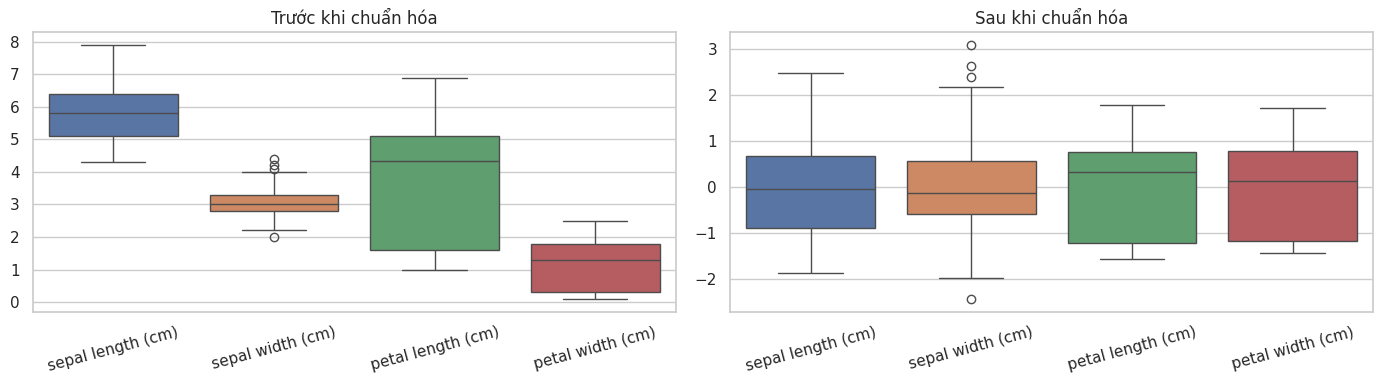

In [12]:
# Vẽ boxplot của dữ liệu TRƯỚC và SAU chuẩn hóa cạnh nhau để so sánh trực quan
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Bên trái: dữ liệu gốc, các hộp có độ cao và vị trí rất khác nhau
sns.boxplot(data=X, ax=axes[0])
axes[0].set_title("Trước khi chuẩn hóa")
axes[0].tick_params(axis="x", rotation=15)  # Nghiêng nhãn để không bị chồng chữ

# Bên phải: dữ liệu đã chuẩn hóa, các hộp đều quanh 0 và có độ rộng tương đương
sns.boxplot(data=X_scaled, ax=axes[1])
axes[1].set_title("Sau khi chuẩn hóa")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### So sánh trước và sau

- **Trước:** các hộp nằm ở những mức giá trị khác nhau, và `petal length` có hộp cao nhất.
- **Sau:** tất cả các hộp tập trung quanh 0 và có biên độ tương đương nhau.
- **Hình dạng từng hộp gần như không đổi** (vị trí trung vị trong hộp, các điểm ngoại lai vẫn còn đó). Chuẩn hóa chỉ "co giãn và dịch chuyển" từng đặc trưng, không làm mất thông tin.

## Chọn số cụm K

K-means yêu cầu ta **phải chọn k trước khi chạy**. Chọn k sai thì dù thuật toán chạy đúng, kết quả vẫn không phản ánh cấu trúc thật của dữ liệu.

Ở bước khám phá, đã đưa ra một dự đoán về k dựa trên biểu đồ. Bây giờ ta sẽ **kiểm chứng dự đoán đó bằng hai phương pháp định lượng**:

1. **Elbow (khuỷu tay)**: dựa trên mức độ "gọn" của các cụm.
2. **Silhouette**: dựa trên mức độ "tách biệt" giữa các cụm.

Cả hai phương pháp đều cần chạy K-means với **nhiều giá trị k khác nhau**, rồi so sánh kết quả.

### Phương pháp Elbow

Sau khi chạy K-means, ta có thể đo độ "gọn" của các cụm bằng **inertia**: tổng bình phương khoảng cách từ mỗi điểm đến tâm cụm của nó.

$$\text{inertia} = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

Đây chính là hàm mục tiêu `J` (SSE, WCSS) ở mục 10.2 của chương; `scikit-learn` gọi nó là `inertia_`.

- Inertia **càng nhỏ** thì các điểm càng sát tâm cụm, tức cụm càng gọn.
- Nhưng inertia **luôn giảm khi tăng k** (nếu k = số mẫu, mỗi điểm là một cụm và inertia bằng 0). Vì vậy ta **không chọn k có inertia nhỏ nhất**, mà tìm điểm mà **từ đó trở đi, tăng k không còn giảm inertia đáng kể**. Trên đồ thị, điểm này trông như một "khuỷu tay".

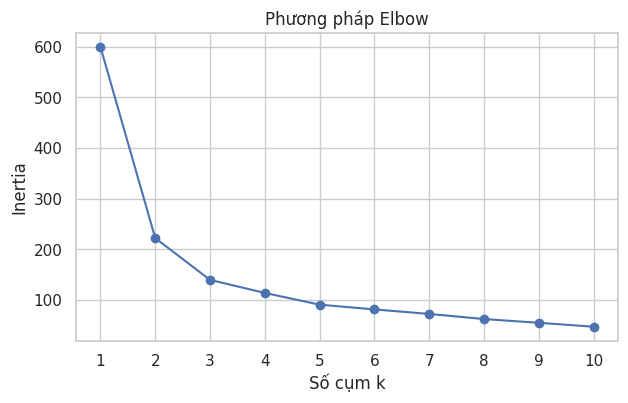

,k,inertia,giảm so với k trước
0,1,600.00,NaN
1,2,222.36,377.64
2,3,139.82,82.54
3,4,114.09,25.73
4,5,90.93,23.17
5,6,81.54,9.38
6,7,72.63,8.91
7,8,62.54,10.09
8,9,55.12,7.42
9,10,47.39,7.73


In [13]:
from sklearn.cluster import KMeans  # Thuật toán K-means của scikit-learn

# Thử k từ 1 đến 10 (k = 1 nghĩa là toàn bộ dữ liệu là một cụm duy nhất)
k_values = range(1, 11)

# Danh sách lưu inertia tương ứng với từng k
inertias = []

for k in k_values:
    # n_clusters=k : số cụm cần tìm
    # n_init=10    : chạy 10 lần với các tâm khởi tạo ngẫu nhiên khác nhau, giữ kết quả tốt nhất
    #                (K-means nhạy với điểm khởi tạo, nên chạy nhiều lần sẽ ổn định hơn)
    # random_state : cố định số ngẫu nhiên để mọi người chạy đều ra cùng kết quả
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)

    # inertia_ là thuộc tính có sẵn sau khi fit
    inertias.append(kmeans.inertia_)

# Vẽ đồ thị Elbow
plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker="o")
plt.xticks(k_values)
plt.xlabel("Số cụm k")
plt.ylabel("Inertia")
plt.title("Phương pháp Elbow")
plt.show()

# In bảng số liệu để quan sát chính xác mức giảm của inertia sau mỗi lần tăng k
elbow_df = pd.DataFrame({"k": list(k_values), "inertia": inertias})

# diff() tính hiệu giữa dòng hiện tại và dòng trước -> cho biết inertia giảm bao nhiêu khi tăng k thêm 1
elbow_df["giảm so với k trước"] = -elbow_df["inertia"].diff()

display(elbow_df.round(2))

**Nhận xét:**

- Inertia **luôn giảm** khi tăng k. Nhưng nếu chọn k quá lớn, ta chia dữ liệu thành quá nhiều nhóm nhỏ, những nhóm này không có ý nghĩa thực tế (hiện tượng **chia quá mức**, tương tự overfitting). Mục tiêu là tìm k **nhỏ nhất** mà vẫn giải thích tốt dữ liệu.
- Từ bảng, mức giảm lớn nhất là từ k = 1 lên k = 2 (600 → 222, giảm khoảng 63%). Tiếp theo là k = 2 lên k = 3 (222 → 140, giảm thêm khoảng 37%). Từ k = 3 trở đi, mỗi bước chỉ giảm thêm khoảng 7 đến 26 đơn vị và đồ thị trở nên thoải hơn.

Vì vậy "khuỷu tay" nằm quanh **k = 2 hoặc k = 3**.

Vấn đề: Điểm "khuỷu tay" trong đồ thị này có rõ ràng không? Điều đó nói lên điều gì về phương pháp Elbow?

Không thật sự rõ: ta khó quyết định giữa k = 2 và k = 3. Đây là hạn chế phổ biến của Elbow: **nó mang tính chủ quan**, nhiều bộ dữ liệu thực tế không có khuỷu tay rõ. Vì vậy ta cần một phương pháp bổ trợ, đó là **Silhouette**.

### Phương pháp Silhouette

Elbow chỉ quan tâm các điểm có gần tâm cụm của mình không. Silhouette xét thêm một điều nữa: các điểm có **xa các cụm khác** không.

Với mỗi điểm, ta tính:

- $a$: khoảng cách trung bình từ điểm đó đến **các điểm cùng cụm** (càng nhỏ càng tốt).
- $b$: khoảng cách trung bình từ điểm đó đến **các điểm của cụm gần nhất khác** (càng lớn càng tốt).

$$s = \frac{b - a}{\max(a, b)}$$

| Giá trị $s$ | Ý nghĩa |
|---|---|
| Gần **1** | Điểm nằm sâu trong cụm của mình, cách xa cụm khác (rất tốt) |
| Gần **0** | Điểm nằm sát ranh giới giữa hai cụm |
| Gần **-1** | Điểm có thể đã bị gán nhầm cụm |

**Silhouette score** của một cách phân cụm là trung bình của $s$ trên tất cả các điểm. Ta chọn k cho **score cao nhất**.

*Lưu ý:* Silhouette **cần ít nhất 2 cụm**, nên ta bắt đầu từ k = 2.

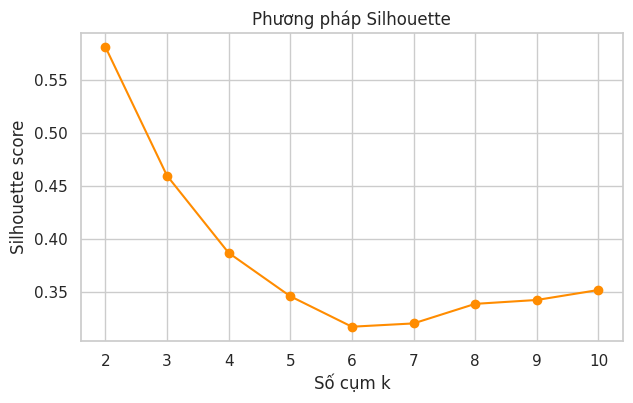

,k,silhouette
0,2,0.582
1,3,0.460
2,4,0.387
8,10,0.352
3,5,0.346
7,9,0.342
6,8,0.339
5,7,0.320
4,6,0.317


In [14]:
from sklearn.metrics import silhouette_score  # Hàm tính silhouette trung bình

sil_scores = []
k_range = range(2, 11)  # Bắt đầu từ 2 vì k = 1 không có "cụm khác" để so sánh

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)

    # fit_predict vừa huấn luyện vừa trả về nhãn cụm (0, 1, ..., k-1) của từng điểm
    labels = kmeans.fit_predict(X_scaled)

    # silhouette_score nhận dữ liệu và nhãn cụm, trả về điểm trung bình toàn bộ mẫu
    sil_scores.append(silhouette_score(X_scaled, labels))

# Vẽ đồ thị Silhouette
plt.figure(figsize=(7, 4))
plt.plot(k_range, sil_scores, marker="o", color="darkorange")
plt.xticks(k_range)
plt.xlabel("Số cụm k")
plt.ylabel("Silhouette score")
plt.title("Phương pháp Silhouette")
plt.show()

# In bảng số liệu, sắp xếp từ cao xuống thấp để thấy k tốt nhất
sil_df = pd.DataFrame({"k": list(k_range), "silhouette": sil_scores})
display(sil_df.sort_values("silhouette", ascending=False).round(3))

**Nhận xét:**

- Silhouette cao nhất ở **k = 2** (0.582), giảm mạnh ở k = 3 (0.460) và k = 4 (0.387), rồi dao động quanh mức thấp 0.32 đến 0.35 khi k lớn (không giảm đều, thấp nhất ở k = 6). Kết quả này khớp với một trong hai khả năng của Elbow (k = 2 hoặc 3) và với nhận xét ở pairplot rằng có hai nhóm tách biệt hẳn (và có thể có các cụm con nhưng không hoàn toàn rõ ràng bằng mắt thường).

**Vấn đề:** Ta biết bộ dữ liệu có **3 loài hoa**. Vậy vì sao Silhouette lại ưu tiên k = 2? Phương pháp này có "sai" không?

Phương pháp không sai: nó đo **độ tách biệt hình học** giữa các cụm, chứ không biết gì về loài hoa. Trong Iris, một loài (setosa) tách hẳn khỏi hai loài còn lại, còn hai loài kia (versicolor và virginica) **chồng lấn nhau** ở một vùng khá lớn. Với thuật toán, hai loài này trông giống một nhóm liền khối hơn là hai nhóm riêng.

**Điều này dẫn đến:**

> **"k tốt nhất theo chỉ số" không nhất thiết trùng với "k đúng theo ý nghĩa thực tế"**. Chỉ số chỉ là công cụ hỗ trợ, quyết định cuối cùng cần kết hợp hiểu biết về bài toán.

Trong bối cảnh của bài toán: Silhouette score của k = 3 thấp hơn k = 2 nhưng vẫn cao hơn mọi k ≥ 4 (0.460 so với tối đa 0.387). Ta **có thể bảo vệ k = 3** nếu có lý do ngoài dữ liệu, ví dụ ta biết trước có 3 loài, hoặc muốn phân biệt chi tiết hơn. Điều quan trọng là **hiểu rõ lý do** cho lựa chọn của mình, thay vì chỉ lấy k có điểm cao nhất.

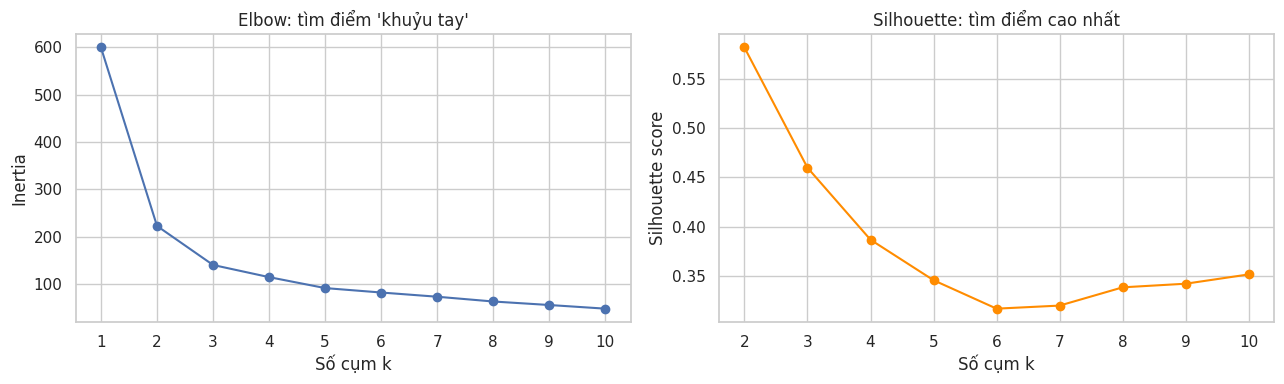

In [15]:
# Vẽ cạnh nhau để so sánh trực tiếp hai phương pháp
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Bên trái: Elbow (k từ 1 đến 10)
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_xticks(list(k_values))
axes[0].set_title("Elbow: tìm điểm 'khuỷu tay'")
axes[0].set_xlabel("Số cụm k")
axes[0].set_ylabel("Inertia")

# Bên phải: Silhouette (k từ 2 đến 10)
axes[1].plot(k_range, sil_scores, marker="o", color="darkorange")
axes[1].set_xticks(list(k_range))
axes[1].set_title("Silhouette: tìm điểm cao nhất")
axes[1].set_xlabel("Số cụm k")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

### So sánh hai phương pháp

| | Elbow | Silhouette |
|---|---|---|
| Đo gì? | Độ gọn của cụm (khoảng cách đến tâm) | Độ gọn **và** độ tách biệt giữa các cụm |
| Cách chọn k | Tìm "khuỷu tay" trên đồ thị | Chọn k có điểm cao nhất |
| Ưu điểm | Nhanh, trực quan | Có con số cụ thể để so sánh |
| Hạn chế | Chủ quan, nhiều khi không có khuỷu tay rõ | Thiên về cụm hình cầu, tách biệt rõ; có thể không khớp với thực tế |

*Lưu ý:* không dựa vào một phương pháp duy nhất. Hãy kết hợp Elbow, Silhouette, biểu đồ trực quan và hiểu biết về bài toán để đưa ra quyết định.

# Huấn luyện K-means và đánh giá kết quả

Sau khi đã có đủ "nguyên liệu": dữ liệu đã chuẩn hóa (`X_scaled`) và các gợi ý về k. Có thể bắt đầu chạy K-means với hai giá trị k và so sánh.

Bắt đầu với **k = 3**. Lý do: ta biết bộ dữ liệu có 3 loài hoa, và k = 3 cũng nằm trong vùng "khuỷu tay" của đồ thị Elbow.

> **Nhắc lại:** K-means **không được thấy nhãn loài**. Nhãn chỉ được dùng ở cuối, để chấm điểm xem các cụm tìm được có khớp với thực tế không.

## K = 3

In [16]:
# Huấn luyện K-means với k = 3 trên dữ liệu đã chuẩn hóa
kmeans3 = KMeans(n_clusters=3, n_init=10, random_state=42)

# fit_predict: học vị trí các tâm cụm và trả về nhãn cụm (0, 1, 2) của từng mẫu
labels3 = kmeans3.fit_predict(X_scaled)

# Gắn nhãn cụm vào BẢN SAO của df để tiện quan sát (không làm thay đổi df gốc)
df_result = df.copy()
df_result["cluster_k3"] = labels3

print(f"Inertia: {kmeans3.inertia_:.2f}")
print(f"Số vòng lặp đến khi hội tụ: {kmeans3.n_iter_}")
print("\nSố mẫu trong mỗi cụm:")
print(df_result["cluster_k3"].value_counts().sort_index())

# cluster_centers_ nằm trong thang ĐÃ CHUẨN HÓA (z-score) nên khó diễn giải
# inverse_transform đưa tâm cụm về đơn vị cm ban đầu
centers3 = pd.DataFrame(
    scaler.inverse_transform(kmeans3.cluster_centers_), columns=X.columns
)
centers3.index.name = "cụm"
display(centers3.round(2))

Inertia: 139.82
Số vòng lặp đến khi hội tụ: 4

Số mẫu trong mỗi cụm:
cluster_k3
0    53
1    50
2    47
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
cụm,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


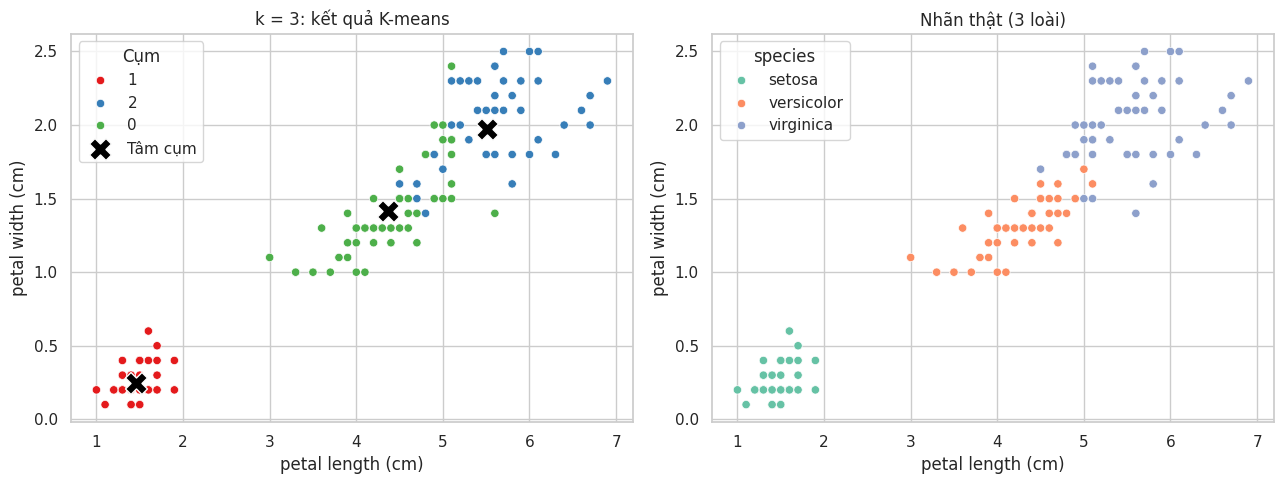

In [ ]:
def plot_clusters(labels, centers, title):
    """Vẽ 2 biểu đồ cạnh nhau: trái tô màu theo cụm tìm được, phải tô màu theo loài thật."""
    _fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Ta vẽ theo 2 đặc trưng về cánh hoa vì chúng phân tách các nhóm tốt nhất (đã thấy ở pairplot)
    # LƯU Ý: K-means dùng cả 4 đặc trưng, biểu đồ chỉ là "lát cắt" 2 chiều dựa trên hai đặc trưng được chúng ta biết là mạnh nhất
    fx, fy = features[2], features[3]

    # Trái: tô màu theo cụm của K-means
    sns.scatterplot(
        x=X[fx], y=X[fy], hue=labels.astype(str), palette="Set1", ax=axes[0]
    )
    # Đánh dấu tâm cụm bằng chữ X đen
    axes[0].scatter(
        centers[fx],
        centers[fy],
        marker="X",
        s=250,
        c="black",
        edgecolor="white",
        label="Tâm cụm",
    )
    axes[0].set_title(f"{title}: kết quả K-means")
    axes[0].legend(title="Cụm")

    # Phải: tô màu theo loài thật để đối chiếu
    sns.scatterplot(x=X[fx], y=X[fy], hue=df["species"], palette="Set2", ax=axes[1])
    axes[1].set_title("Nhãn thật (3 loài)")

    plt.tight_layout()
    plt.show()


plot_clusters(labels3, centers3, "k = 3")

**Nhận xét:**

Hai biểu đồ có các điểm giống và khác:

- **Giống:** nhóm cánh hoa nhỏ (góc dưới bên trái) được tách ra gần như hoàn toàn trùng khớp với một loài.
- **Khác:** ở vùng giữa, nơi hai loài còn lại tiếp giáp nhau, ranh giới do K-means vẽ ra **không trùng khít** với ranh giới thật. Một số điểm bị gán sang cụm khác với loài của chúng.

Hai loài này trên thực tế **chồng lấn nhau** trong không gian đặc trưng, nên không có đường ranh giới nào tách hoàn hảo.

**Đánh giá: so sánh cụm với nhãn thật**

Vì số thứ tự cụm là tùy ý (cụm "0" của K-means không nhất thiết ứng với loài có `target = 0`), ta dùng các cách đánh giá không phụ thuộc vào cách đánh số:

1. **Bảng chéo (crosstab):** mỗi dòng là một loài thật, mỗi cột là một cụm, mỗi ô đếm số mẫu. Nếu mỗi dòng chỉ có số lớn ở một cột thì các cụm khớp tốt với loài.
2. **Adjusted Rand Index (ARI):** một con số tóm tắt mức độ trùng khớp giữa hai cách chia nhóm.
3. **Số mẫu "lệch":** mỗi cụm lấy loài chiếm đa số làm đại diện, rồi đếm các mẫu thuộc loài khác.

Ngoài ra code cũng in **Silhouette** để so với ARI: Silhouette là chỉ số **nội bộ** (không cần nhãn), còn ARI là chỉ số **ngoại** (cần nhãn thật).

| Giá trị ARI | Ý nghĩa |
|---|---|
| **1** | Hai cách chia giống hệt nhau (bất kể cách đánh số) |
| **Gần 0** | Không tốt hơn việc chia ngẫu nhiên |
| **Âm** | Tệ hơn ngẫu nhiên |

In [18]:
from sklearn.metrics import adjusted_rand_score  # Chỉ số ARI

# 1) Bảng chéo: loài thật (dòng) x cụm tìm được (cột)
ct3 = pd.crosstab(df["species"], labels3, rownames=["Loài thật"], colnames=["Cụm"])
display(ct3)

# 2) ARI: so sánh nhãn thật (cột target: 0, 1, 2) với nhãn cụm
ari3 = adjusted_rand_score(df["target"], labels3)

# 3) Silhouette: chỉ số nội bộ, KHÔNG cần nhãn thật (dùng được cả khi thực tế không có đáp án)
sil3 = silhouette_score(X_scaled, labels3)

print(f"ARI (so với 3 loài thật): {ari3:.3f}")
print(f"Silhouette score:         {sil3:.3f}")

# 4) Đếm số mẫu "lệch": với mỗi cụm, lấy loài chiếm đa số làm loài đại diện của cụm đó
# (chỉ có nghĩa khi mỗi cụm tương ứng với một loài khác nhau)
cluster_to_species = pd.crosstab(labels3, df["species"]).idxmax(axis=1)
predicted_species = pd.Series(labels3).map(cluster_to_species)
mismatch = predicted_species.values != df["species"].astype(str).values
print(f"Số mẫu nằm ở cụm không khớp với loài của nó: {mismatch.sum()}/150")

Cụm,0,1,2
Loài thật,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


ARI (so với 3 loài thật): 0.620
Silhouette score:         0.460
Số mẫu nằm ở cụm không khớp với loài của nó: 25/150


**Nhận xét K = 3:**

- **setosa** tách hoàn hảo: cả 50 mẫu nằm trong một cụm riêng, không lẫn mẫu nào khác.
- **versicolor** và **virginica** bị lẫn vào nhau: 11 mẫu versicolor nằm trong cụm của virginica và 14 mẫu virginica nằm trong cụm của versicolor, tổng cộng **25/150** mẫu "lệch".
- ARI = 0.620: cao hơn hẳn mức ngẫu nhiên (gần 0) nhưng còn xa 1, khớp với việc hai loài kia chồng lấn.
- Silhouette = 0.460 thấp hơn k = 2: đúng như đã thấy ở bước chọn k, ranh giới giữa hai cụm này không rõ.

## K = 2

Ở bước chọn k, Silhouette cho điểm cao nhất tại **k = 2**. Ta chạy lại với k = 2 và xem nó khác k = 3 như thế nào.

Lần này cần cẩn thận khi đánh giá: nhãn thật có **3 loài**, nhưng ta chỉ yêu cầu **2 cụm**. Vì vậy ngoài việc so sánh với 3 loài, ta sẽ so sánh thêm với một cách chia khác là **"setosa" và "không phải setosa"**.

Inertia: 222.36

Số mẫu trong mỗi cụm:
0    100
1     50
Name: count, dtype: int64

Tâm cụm (đơn vị cm):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
cụm,,,,
0,6.26,2.87,4.91,1.68
1,5.01,3.43,1.46,0.25


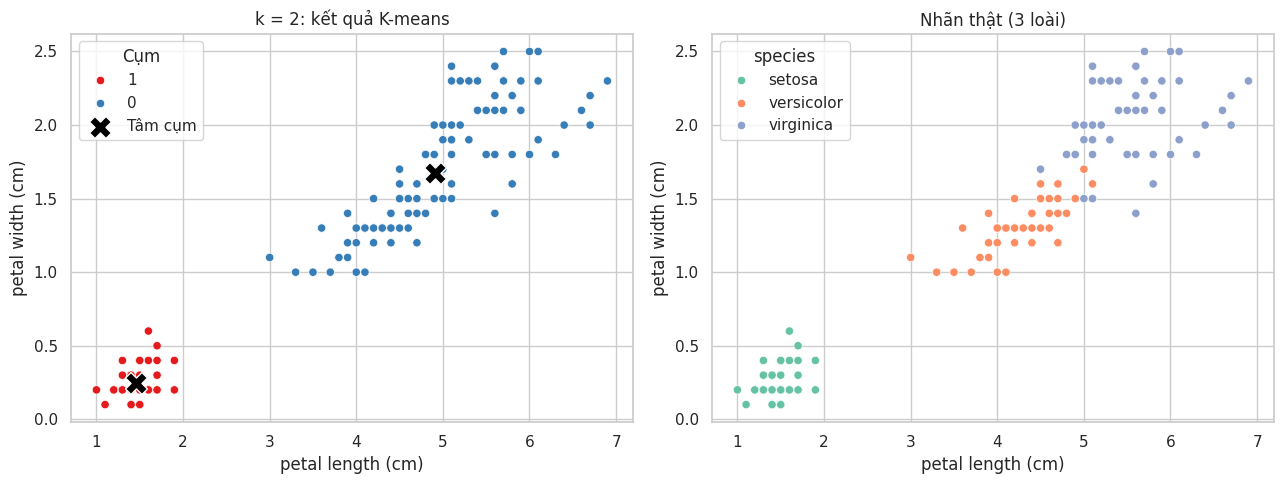

Cụm,0,1
Loài thật,,
setosa,0,50
versicolor,50,0
virginica,50,0


ARI (so với 3 loài):             0.568
ARI (so với setosa / không):     1.000
Silhouette score:                0.582


In [19]:
# Huấn luyện K-means với k = 2
kmeans2 = KMeans(n_clusters=2, n_init=10, random_state=42)
labels2 = kmeans2.fit_predict(X_scaled)

# Đưa tâm cụm về đơn vị cm để diễn giải
centers2 = pd.DataFrame(
    scaler.inverse_transform(kmeans2.cluster_centers_), columns=X.columns
)
centers2.index.name = "cụm"

print(f"Inertia: {kmeans2.inertia_:.2f}")
print("\nSố mẫu trong mỗi cụm:")
print(pd.Series(labels2).value_counts().sort_index())
print("\nTâm cụm (đơn vị cm):")
display(centers2.round(2))

# Biểu đồ: dùng lại hàm đã viết ở phần k = 3
plot_clusters(labels2, centers2, "k = 2")

# Đánh giá k = 2 theo 2 cách

# Cách 1: so với 3 loài thật
ct2 = pd.crosstab(df["species"], labels2, rownames=["Loài thật"], colnames=["Cụm"])
display(ct2)
ari2_species = adjusted_rand_score(df["target"], labels2)

# Cách 2: so với cách chia 2 nhóm "setosa" (target = 0) và "không phải setosa"
is_setosa = (df["target"] == 0).astype(int)
ari2_binary = adjusted_rand_score(is_setosa, labels2)

sil2 = silhouette_score(X_scaled, labels2)

print(f"ARI (so với 3 loài):             {ari2_species:.3f}")
print(f"ARI (so với setosa / không):     {ari2_binary:.3f}")
print(f"Silhouette score:                {sil2:.3f}")

**Nhận xét**

- Một cụm chứa đúng 50 mẫu **setosa** (không lẫn mẫu nào khác). Cụm còn lại (100 mẫu) gộp **versicolor và virginica** lại với nhau.

Đây chính xác là cấu trúc mà ta đã đoán từ pairplot và histogram: một nhóm tách biệt hẳn, phần còn lại liền khối.

- ARI so với 3 loài ở k = 2 thấp hơn k = 3. Tuy vậy không có nghĩa là k = 2 "tệ hơn". So sánh này **không công bằng**: nhãn thật có 3 nhóm mà ta chỉ cho phép 2 cụm, nên ARI chắc chắn bị kéo xuống. Khi so với cách chia **setosa / không phải setosa**, ARI ở k = 2 cao hơn hẳn.

K = 2 và k = 3 là **hai câu trả lời cho hai câu hỏi khác nhau**: "đâu là cấu trúc tách biệt rõ nhất?" (k = 2) và "có thể phân biệt cả ba loài không?" (k = 3).

> Việc chọn `k` phải tuỳ thuộc vào nhu cầu của bài toán, nếu là để phân biệt loài thì chọn **k = 3**. Nếu muốn tìm cấu trúc tự nhiên nhất mà không biết trước số nhóm thật sự, **k = 2** là kết luận hợp lý mà bước phân tích dữ liệu đã đưa ra.

## Bảng tổng hợp

In [20]:
# Bảng tổng hợp so sánh k = 3 và k = 2
summary = pd.DataFrame(
    {
        "k": [3, 2],
        "Inertia": [kmeans3.inertia_, kmeans2.inertia_],
        "Silhouette": [sil3, sil2],
        "ARI (so với 3 loài)": [ari3, ari2_species],
    }
).set_index("k")

display(summary.round(3))

,Inertia,Silhouette,ARI (so với 3 loài)
k,,,
3,139.820,0.460,0.620
2,222.362,0.582,0.568


| Chỉ số | Nên đọc thế nào |
|---|---|
| **Inertia** | **Không so sánh được giữa các k**: k lớn hơn luôn cho inertia nhỏ hơn. Chỉ dùng để tìm khuỷu tay. |
| **Silhouette** | Chỉ số nội bộ (không cần nhãn thật). k = 2 cao hơn vì các cụm tách biệt rõ hơn. |
| **ARI** | Chỉ số ngoại (cần nhãn thật). k = 3 cao hơn vì khớp với số loài thật. |

**Điểm mấu chốt:** Silhouette và ARI cho hai kết luận khác nhau, vì chúng trả lời hai câu hỏi khác nhau. Không có chỉ số nào "đúng tuyệt đối".

# Tổng kết

- Khám phá dữ liệu giúp ta hiểu cấu trúc dữ liệu và đưa ra giả thuyết về k (siêu tham số) **trước khi** chạy thuật toán.
- Chuẩn hóa giúp các đặc trưng đóng góp công bằng vào khoảng cách, nhưng không đảm bảo kết quả tốt hơn trong mọi trường hợp (có thể thực hiện lại thuật toán K-means trên dữ liệu chưa chuẩn hóa để quan sát kết quả lựa chọn K và so sánh ARI).
- Chọn k cần kết hợp nhiều nguồn thông tin (Elbow, Silhouette, biểu đồ, hiểu biết về bài toán).
- Cụm tìm được là cấu trúc hình học của dữ liệu, không nhất thiết trùng với nhãn do con người đặt.
- K-means chỉ đạt **cực tiểu địa phương** và phụ thuộc tâm khởi tạo (mục 10.3.2, 10.5.1): ta dùng `n_init=10` (giữ lần chạy có inertia nhỏ nhất) và cố định `random_state=42` để kết quả lặp lại được.